# NLP Lab Assignment 9 — Hindi POS Tagging
## Maximum Entropy Markov Models (MEMM) & Conditional Random Fields (CRF)
### A Comparative Study: Naive Bayes vs. HMM vs. MEMM vs. CRF

---

### Assignment Requirements & Objectives:
1. **Maximum Entropy Markov Model (MEMM)**:
   - Implement an MEMM on the training dataset and evaluate it on the dev and test sets.
   - Reference: [arne-cl/nltk-maxent-pos-tagger](https://github.com/arne-cl/nltk-maxent-pos-tagger) based on Ratnaparkhi's (1996) Maximum Entropy POS tagger.
2. **Conditional Random Field (CRF) POS Tagger**:
   - Implement a CRF based POS tagger on the training dataset and evaluate on the dev and test sets.
   - Reference: [sklearn-crfsuite tutorial](https://sklearn-crfsuite.readthedocs.io/en/latest/tutorial.html).
   - Mandatory Features:
     - **a. Prefixes Upto Length 4** (Prefix lengths 1, 2, 3, 4): If a prefix of that length is not found, feature value = `'NULL'`.
     - **b. Suffixes Upto Length 4** (Suffix lengths 1, 2, 3, 4): If a suffix of that length is not found, feature value = `'NULL'`.
     - **c. Context Features**: Previous Word ($w_{i-1}$), Current Word ($w_i$), Next Word ($w_{i+1}$) with boundary handling.
     - **d. Binary Length Feature**: If length of the word is $\le 4$, `length_feature = 'LESS'`; otherwise `'MORE'`.
3. **Comprehensive Comparative Study**:
   - Compare performance between **Naive Bayes**, **HMM** (developed in Assignment 7), **MEMM**, and **CRF**.
   - Compare performance across each tag and plot grouped bar charts.

---

### Theoretical Comparison: Generative vs. Discriminative Sequence Modeling

| Model | Family | Objective Function | Normalization | Label Bias Problem? | Overlapping Features? |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Naive Bayes** | Generative | Joint $P(X, Y) = P(Y) \prod_j P(x_j \mid Y)$ | Global (over joint space) | No | No (Assumes independence) |
| **HMM** | Generative | Joint $P(X, Y) = \prod_t P(y_t \mid y_{t-1}) P(w_t \mid y_t)$ | Local transition & emission | No | No (Strict emission independence) |
| **MEMM** | Discriminative | Conditional $P(Y \mid X) = \prod_t P(y_t \mid x_t, y_{t-1})$ | **Local** per state $Z(x_t, y_{t-1})$ | **Yes** (Susceptible) | **Yes** (Arbitrary overlapping features) |
| **CRF** | Discriminative | Conditional $P(Y \mid X) = \frac{1}{Z(X)} \exp(\sum_t \dots)$ | **Global** over sequence $Z(X)$ | **No** (Immune) | **Yes** (Arbitrary overlapping features) |

#### Key Concepts Explained:
1. **Generative vs. Discriminative Sequence Modeling:**
   - Generative models (Naive Bayes & HMM) model the joint probability $P(X, Y) = P(X \mid Y) P(Y)$. Because they must generate the observations $X$, they are forced to assume words are conditionally independent given states. This prevents using rich overlapping features like character prefixes, suffixes, and neighboring context words.
   - Discriminative models (MEMM & CRF) directly model the conditional distribution $P(Y \mid X)$. Because they condition on $X$ rather than generating it, they can incorporate any arbitrary, non-independent, overlapping morphological and contextual features.
2. **Local vs. Global Normalization (The Label Bias Problem):**
   - In an MEMM, the probability distribution is locally normalized at each time step $t$:
     $$P(y_t \mid x_t, y_{t-1}) = \frac{\exp\left(\mathbf{w}^T \mathbf{f}(x_t, y_{t-1}, y_t)\right)}{\sum_{y'} \exp\left(\mathbf{w}^T \mathbf{f}(x_t, y_{t-1}, y')\right)}$$
     Because probabilities leaving state $y_{t-1}$ must sum to $1$, states with low entropy (few outgoing transitions) transfer almost all probability mass to those few successors regardless of whether the observation $x_t$ supports them. Upstream mistakes cannot be corrected by downstream evidence.
   - Linear-Chain CRFs eliminate label bias by normalizing globally over the entire sequence via a global partition function $Z(X)$:
     $$P(Y \mid X) = \frac{1}{Z(X)} \prod_{t=1}^T \exp\left( \sum_k \lambda_k f_k(y_t, X, t) + \sum_j \mu_j g_j(y_{t-1}, y_t, X, t) \right)$$
     This allows downstream tokens and transitions to influence and correct earlier POS tag decisions.


In [1]:
import os
import sys
import time
import zipfile
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_fscore_support, accuracy_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
import sklearn_crfsuite

# Configure notebook rendering and styling
%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
sns.set_theme(style="whitegrid")

# Special boundary tokens
START, END, UNK = "<S>", "</S>", "<UNK>"

# Robust Data Directory Resolution (handles running from workspace root or Assignment9/ folder)
candidate_dirs = [
    "Hindi-POS-Data",
    os.path.join("Assignment9", "Hindi-POS-Data"),
    os.path.join("..", "Hindi-POS-Data"),
]
DATA_DIR = next((d for d in candidate_dirs if os.path.isdir(d)), None)

if DATA_DIR is None:
    # Auto-extract from zip if directory is not found
    candidate_zips = [
        "Hindi-POS-Data.zip",
        os.path.join("Assignment9", "Hindi-POS-Data.zip"),
        os.path.join("..", "Hindi-POS-Data.zip")
    ]
    zip_path = next((z for z in candidate_zips if os.path.exists(z)), None)
    if zip_path:
        extract_target = os.path.dirname(zip_path) or "."
        print(f"Extracting {zip_path} into {extract_target}...")
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(extract_target)
        DATA_DIR = os.path.join(extract_target, "Hindi-POS-Data")

# Output directories for CSV summaries and charts
OUT_DIR = os.path.join(os.path.dirname(DATA_DIR), "results") if os.path.dirname(DATA_DIR) else "results"
CHARTS_DIR = os.path.join(OUT_DIR, "charts")
os.makedirs(CHARTS_DIR, exist_ok=True)

print(f"Data directory located at  : {DATA_DIR}")
print(f"Results directory set to   : {OUT_DIR}")


Data directory located at  : Hindi-POS-Data
Results directory set to   : results


## 1. Dataset Loading and Exploration

The dataset is a POS-annotated Hindi corpus using the **Bureau of Indian Standards (BIS)** tagset.
- `hindi-train-pos.txt`: 15,087 sentences, 325,710 tokens
- `hindi-dev-pos.txt`: 1,866 sentences, 40,762 tokens
- `hindi-test-pos.txt`: 1,910 sentences, 41,415 tokens

Each line has `<word> <tag>`, and blank lines indicate sentence boundaries.


In [2]:
def read_pos_file(path):
    """
    Reads a POS-tagged file.
    Format: Each line is `<word> <tag>`. Blank lines denote sentence boundaries.
    Returns: List of sentences, where each sentence is a tuple: (words, tags).
    """
    sents, words, tags = [], [], []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line.strip():
                if words:
                    sents.append((words, tags))
                    words, tags = [], []
                continue
            parts = line.split()
            words.append(parts[0])
            tags.append(parts[-1])
    if words:
        sents.append((words, tags))
    return sents

# Load datasets
train_sents = read_pos_file(os.path.join(DATA_DIR, "hindi-train-pos.txt"))
dev_sents   = read_pos_file(os.path.join(DATA_DIR, "hindi-dev-pos.txt"))
test_sents  = read_pos_file(os.path.join(DATA_DIR, "hindi-test-pos.txt"))

print("=" * 65)
print("DATASET SUMMARY STATISTICS")
print("=" * 65)
print(f"  Training Set   : {len(train_sents):6d} sentences | {sum(len(w) for w, _ in train_sents):7d} tokens")
print(f"  Development Set: {len(dev_sents):6d} sentences | {sum(len(w) for w, _ in dev_sents):7d} tokens")
print(f"  Test Set       : {len(test_sents):6d} sentences | {sum(len(w) for w, _ in test_sents):7d} tokens")

# Canonical tag ordering by training set frequency
tag_freq = Counter(t for _, ts in train_sents for t in ts)
labels = [t for t, _ in tag_freq.most_common()]

print(f"\nTotal Unique POS Tags: {len(labels)}")
print("Top 10 Most Frequent Tags:", labels[:10])

print("\nSample Hindi Sentence (First 10 tokens):")
for w, t in zip(train_sents[0][0][:10], train_sents[0][1][:10]):
    print(f"  {w:16s} --> {t}")


DATASET SUMMARY STATISTICS
  Training Set   :  15087 sentences |  325710 tokens
  Development Set:   1866 sentences |   40762 tokens
  Test Set       :   1910 sentences |   41415 tokens

Total Unique POS Tags: 24
Top 10 Most Frequent Tags: ['N_NN', 'PSP', 'N_NNP', 'V_VM', 'V_VAUX', 'RD_PUNC', 'JJ', 'PR_PRP', 'QT_QTC', 'CC_CCD']

Sample Hindi Sentence (First 10 tokens):
  यह               --> DM_DMD
  एशिया            --> N_NNP
  की               --> PSP
  सबसे             --> RP_INTF
  बड़ी              --> JJ
  मस्जिदों         --> N_NN
  में              --> PSP
  से               --> PSP
  एक               --> QT_QTC
  है               --> V_VM


## 2. Feature Extraction (Questions 2a, 2b, 2c, 2d)

The assignment requires extracting four specific feature families for each word $w_i$:
1. **Prefixes Upto Length 4** (Lengths 1, 2, 3, 4):
   - Features: `prefix_1`, `prefix_2`, `prefix_3`, `prefix_4`.
   - *Requirement:* If a prefix of length $k$ is not found ($	ext{len}(w_i) < k$), set `prefix_k = 'NULL'`.
2. **Suffixes Upto Length 4** (Lengths 1, 2, 3, 4):
   - Features: `suffix_1`, `suffix_2`, `suffix_3`, `suffix_4`.
   - *Requirement:* If a suffix of length $k$ is not found ($	ext{len}(w_i) < k$), set `suffix_k = 'NULL'`.
3. **Context Features**:
   - `prev_word`: $w_{i-1}$ (or `'<START>'` if $i=0$).
   - `word`: $w_i$ (current word).
   - `next_word`: $w_{i+1}$ (or `'</S>'` if $i=N-1$).
4. **Binary Length Feature**:
   - If length of the word $\le 4$, `length_feature = 'LESS'`; otherwise `'MORE'`.

### Why These Features are Vital in Hindi POS Tagging:
- **Agglutinative Suffixes:** Suffixes strongly encode grammatical roles:
  - Postpositions (`PSP`): e.g., **-ने**, **-को**, **-में**, **-से**, **-का**, **-की**.
  - Verb inflections (`V_VM`): e.g., **-ता**, **-ती**, **-ते** (habitual), **-या**, **-ई**, **-ए** (perfective), **-कर** (conjunctive participle).
- **Prefixes:** Help identify derived and negative nominals/adjectives (e.g., **अ-**, **निर्-**, **उप-**, **प्रति-**).
- **Word Length:** Distinguishes closed-class function words (postpositions, conjunctions, particles are almost always $\le 4$ characters) from open-class nouns and adjectives ($> 4$ characters).


In [3]:
def extract_word_features(words, i):
    """
    Extracts the four required feature families for word words[i]:
      a. Prefixes Upto Length 4 (with 'NULL' padding if len < k)
      b. Suffixes Upto Length 4 (with 'NULL' padding if len < k)
      c. Context Features: Previous Word, Current Word, Next Word
      d. Binary Length Feature: 'LESS' if len <= 4 else 'MORE'
    """
    w = words[i]
    n = len(w)

    feats = {
        # Feature (d): Binary Length Feature
        "length_feature": "LESS" if n <= 4 else "MORE",

        # Feature (c): Context Features
        "word": w,
        "prev_word": words[i - 1] if i > 0 else START,
        "next_word": words[i + 1] if i < len(words) - 1 else END,

        # Feature (a): Prefixes Upto Length 4 (lengths 1, 2, 3, 4)
        "prefix_1": w[:1] if n >= 1 else "NULL",
        "prefix_2": w[:2] if n >= 2 else "NULL",
        "prefix_3": w[:3] if n >= 3 else "NULL",
        "prefix_4": w[:4] if n >= 4 else "NULL",

        # Feature (b): Suffixes Upto Length 4 (lengths 1, 2, 3, 4)
        "suffix_1": w[-1:] if n >= 1 else "NULL",
        "suffix_2": w[-2:] if n >= 2 else "NULL",
        "suffix_3": w[-3:] if n >= 3 else "NULL",
        "suffix_4": w[-4:] if n >= 4 else "NULL",
    }
    return feats

# Verify feature extractor on short and long Hindi words
sample_short = ["वह", "घर", "गया"]
sample_long = ["अंतर्राष्ट्रीय", "संबंध"]

print("Feature Extractor Test for Short Word 'वह' (len=2, with 'NULL' padding):")
for k, v in extract_word_features(sample_short, 0).items():
    print(f"  {k:15s} : {v}")

print("\nFeature Extractor Test for Long Word 'अंतर्राष्ट्रीय' (len=11, full prefixes/suffixes):")
for k, v in extract_word_features(sample_long, 0).items():
    print(f"  {k:15s} : {v}")


Feature Extractor Test for Short Word 'वह' (len=2, with 'NULL' padding):
  length_feature  : LESS
  word            : वह
  prev_word       : <S>
  next_word       : घर
  prefix_1        : व
  prefix_2        : वह
  prefix_3        : NULL
  prefix_4        : NULL
  suffix_1        : ह
  suffix_2        : वह
  suffix_3        : NULL
  suffix_4        : NULL

Feature Extractor Test for Long Word 'अंतर्राष्ट्रीय' (len=11, full prefixes/suffixes):
  length_feature  : MORE
  word            : अंतर्राष्ट्रीय
  prev_word       : <S>
  next_word       : संबंध
  prefix_1        : अ
  prefix_2        : अं
  prefix_3        : अंत
  prefix_4        : अंतर
  suffix_1        : य
  suffix_2        : ीय
  suffix_3        : रीय
  suffix_4        : ्रीय


## 3. Maximum Entropy Markov Model (MEMM) (Question 1)

### Architecture and Reference:
Following [arne-cl/nltk-maxent-pos-tagger](https://github.com/arne-cl/nltk-maxent-pos-tagger) and Ratnaparkhi (1996):
1. **Mathematical Formulation:**
   The tag probability at position $t$ is modeled as a multinomial log-linear / Maximum Entropy distribution conditioned on both the observation features $x_t$ and the previous tag $y_{t-1}$:
   $$P(y_t \mid x_t, y_{t-1}) = rac{\exp\left(\mathbf{w}_{y_t}^T \mathbf{f}(x_t, y_{t-1})ight)}{\sum_{y'} \exp\left(\mathbf{w}_{y'}^T \mathbf{f}(x_t, y_{t-1})ight)}$$
2. **Markov Property:**
   The feature vector includes all observation features (prefixes, suffixes, context words, length) plus the previous tag feature `prev_tag = y_{t-1}` (or `'<START>'` for $t=0$).
3. **High-Performance Implementation:**
   - In `arne-cl`, training relied on an external 2008 O'Caml executable (`MEGAM`) which is deprecated and unavailable on modern platforms.
   - We utilize `scikit-learn`'s L-BFGS solver to optimize the identical Maximum Entropy (cross-entropy with $L_2$ regularization) objective in C++.
   - **Vectorized Inference:** Observation features $x_t$ depend only on the input sentence words and are completely static with respect to $y_{t-1}$. We precompute static scores for all tokens via a single matrix product $\mathbf{X}_{obs} \mathbf{W}_{obs}^T + \mathbf{b}$, reducing inference time to fractions of a second across the entire test corpus.


In [4]:
class MEMMTagger:
    """
    Maximum Entropy Markov Model (MEMM) POS Tagger.
    Based on Ratnaparkhi (1996) and arne-cl/nltk-maxent-pos-tagger.
    
    Conditioning: P(y_t | x_t, y_{t-1})
    Features: observation features (prefixes, suffixes, context words, length) + prev_tag (Markov transition).
    Optimizer: L-BFGS Maximum Entropy / Multinomial Logistic Regression.
    """
    def __init__(self, C=1.0, max_iter=100):
        self.C = C
        self.max_iter = max_iter
        self.vec = DictVectorizer(sparse=True)
        self.clf = LogisticRegression(
            C=self.C,
            max_iter=self.max_iter,
            solver="lbfgs",
            random_state=42
        )

    def fit(self, sents):
        train_feats = []
        train_labels = []
        for words, tags in sents:
            for i, t in enumerate(tags):
                pt = tags[i - 1] if i > 0 else START
                f = extract_word_features(words, i)
                f["prev_tag"] = pt
                train_feats.append(f)
                train_labels.append(t)

        print(f"  [MEMM] Vectorizing {len(train_feats)} token instances...")
        X_train = self.vec.fit_transform(train_feats)
        print(f"  [MEMM] Feature matrix shape: {X_train.shape} (instances x features)")
        print(f"  [MEMM] Optimizing Maximum Entropy weights with L-BFGS...")
        self.clf.fit(X_train, train_labels)

        self.classes = self.clf.classes_
        self.n_classes = len(self.classes)
        self.class_to_idx = {c: i for i, c in enumerate(self.classes)}

        # Precompute transition weight table: trans_weights[prev_tag_idx, cur_tag_idx]
        self.all_prev_tags = list(self.classes) + [START]
        self.prev_tag_to_idx = {pt: i for i, pt in enumerate(self.all_prev_tags)}
        self.trans_weights = np.zeros((len(self.all_prev_tags), self.n_classes))

        for pt, p_idx in self.prev_tag_to_idx.items():
            feat_name = f"prev_tag={pt}"
            if feat_name in self.vec.vocabulary_:
                f_idx = self.vec.vocabulary_[feat_name]
                self.trans_weights[p_idx] = self.clf.coef_[:, f_idx]

        return self

    def predict_sents(self, sents):
        """
        Vectorized batch sentence prediction:
        1. Computes all static observation scores in batch via matrix multiplication.
        2. Applies sequential Markov decoding word-by-word.
        """
        obs_feats = []
        sent_lens = []
        for words, _ in sents:
            sent_lens.append(len(words))
            for i in range(len(words)):
                obs_feats.append(extract_word_features(words, i))

        X_obs = self.vec.transform(obs_feats)
        obs_scores = (X_obs @ self.clf.coef_.T) + self.clf.intercept_

        out_preds = []
        offset = 0
        start_idx = self.prev_tag_to_idx[START]

        for L in sent_lens:
            prev_idx = start_idx
            sent_pred = []
            for pos in range(offset, offset + L):
                scores = obs_scores[pos] + self.trans_weights[prev_idx]
                best_c = int(np.argmax(scores))
                best_tag = self.classes[best_c]
                sent_pred.append(best_tag)
                prev_idx = self.prev_tag_to_idx.get(best_tag, start_idx)
            offset += L
            out_preds.append(sent_pred)

        return out_preds

# Train MEMM
print("Training MEMM Tagger on Hindi Training Set...")
t0 = time.time()
memm_model = MEMMTagger(C=1.0, max_iter=100).fit(train_sents)
memm_train_time = time.time() - t0
print(f"MEMM training completed in {memm_train_time:.2f} seconds.")


Training MEMM Tagger on Hindi Training Set...


  [MEMM] Vectorizing 325710 token instances...


  [MEMM] Feature matrix shape: (325710, 88753) (instances x features)
  [MEMM] Optimizing Maximum Entropy weights with L-BFGS...


MEMM training completed in 40.37 seconds.


C:\Users\Lenovo\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 4. Conditional Random Field (CRF) POS Tagger (Question 2)

### Theory & Setup:
Following the official [`sklearn-crfsuite` tutorial](https://sklearn-crfsuite.readthedocs.io/en/latest/tutorial.html):
- Linear-chain CRFs model the conditional distribution of the entire label sequence $Y = (y_1, \dots, y_T)$ given input $X = (x_1, \dots, x_T)$:
  $$P(Y \mid X) = rac{1}{Z(X)} \exp\left( \sum_{t=1}^T \sum_k \lambda_k f_k(y_t, X, t) + \sum_{t=1}^T \sum_j \mu_j g_j(y_{t-1}, y_t, X, t) ight)$$
- The normalization constant $Z(X)$ is computed globally over all possible sequences via the **Forward-Backward** algorithm.
- **Why this eliminates the Label Bias Problem:** Unlike MEMM where transition probabilities must normalize to $1$ at every single node locally, CRF optimizes the global sequence likelihood. Low-entropy states do not artificially trap probability mass, allowing transitions and emissions to compete fairly across the entire sequence.
- **Regularization:** Elastic net ($L_1$ penalty $c_1=0.1$ for feature sparsity, $L_2$ penalty $c_2=0.1$ to prevent weight explosion).


In [5]:
class CRFTagger:
    """
    Linear-chain Conditional Random Field (CRF) POS Tagger using sklearn-crfsuite.
    Trained with L-BFGS, elastic-net regularization (c1=0.1, c2=0.1).
    """
    def __init__(self, c1=0.1, c2=0.1, max_iterations=50):
        self.crf = sklearn_crfsuite.CRF(
            algorithm="lbfgs",
            c1=c1,
            c2=c2,
            max_iterations=max_iterations,
            all_possible_transitions=True,
            verbose=False
        )

    @staticmethod
    def _sent2features(words):
        return [extract_word_features(words, i) for i in range(len(words))]

    def fit(self, sents):
        print("  [CRF] Converting sentences to token feature dictionaries...")
        X_train = [self._sent2features(w) for w, _ in sents]
        y_train = [t for _, t in sents]
        print(f"  [CRF] Fitting linear-chain CRF on {len(X_train)} sentences...")
        self.crf.fit(X_train, y_train)
        return self

    def predict_sents(self, sents):
        X = [self._sent2features(w) for w, _ in sents]
        return self.crf.predict(X)

# Train CRF
print("Training CRF Tagger on Hindi Training Set...")
t0 = time.time()
crf_model = CRFTagger(c1=0.1, c2=0.1, max_iterations=50).fit(train_sents)
crf_train_time = time.time() - t0
print(f"CRF training completed in {crf_train_time:.2f} seconds.")


Training CRF Tagger on Hindi Training Set...
  [CRF] Converting sentences to token feature dictionaries...


  [CRF] Fitting linear-chain CRF on 15087 sentences...


CRF training completed in 24.54 seconds.


## 5. Baseline Models from Assignment 7 (Naive Bayes & HMM)

To fulfill Question 3 (Comparative Study), we import and train the exact Naive Bayes and Hidden Markov Model taggers developed in Assignment 7:
1. **Naive Bayes Tagger**: Point-wise generative classifier with add-$\alpha$ smoothing:
   $$P(\text{tag} \mid \text{feats}) \propto P(\text{tag}) \prod_f P(\text{feat}_f \mid \text{tag})$$
2. **Bigram HMM Tagger**: First-order Hidden Markov Model with transition matrix $A$, emission matrix $B$, and Forward Viterbi sequence decoding:
   $$\hat{Y} = \arg\max_Y \prod_{t=1}^T P(y_t \mid y_{t-1}) P(w_t \mid y_t)$$


In [6]:
class NaiveBayesTagger:
    """
    Point-wise Naive Bayes Tagger with add-alpha smoothing (from Assignment 7).
    """
    FEATS = ["len", "word", "prev_word", "next_word", "prev_tag"]

    def __init__(self, alpha=0.1):
        self.alpha = alpha

    @staticmethod
    def _feats(words, i, prev_tag):
        w = words[i]
        return {
            "len": "MORE" if len(w) > 4 else "LESS",
            "word": w,
            "prev_word": words[i - 1] if i > 0 else START,
            "next_word": words[i + 1] if i < len(words) - 1 else END,
            "prev_tag": prev_tag,
        }

    def fit(self, sents):
        self.tags = sorted({t for _, ts in sents for t in ts})
        self.tag_idx = {t: i for i, t in enumerate(self.tags)}
        T = len(self.tags)
        self.tag_count = np.zeros(T)
        cnt = {f: defaultdict(lambda: np.zeros(T)) for f in self.FEATS}
        for words, tags in sents:
            prev = START
            for i, t in enumerate(tags):
                ti = self.tag_idx[t]
                self.tag_count[ti] += 1
                for f, v in self._feats(words, i, prev).items():
                    cnt[f][v][ti] += 1
                prev = t
        self.log_prior = np.log(self.tag_count / self.tag_count.sum())
        self.vocab = {}
        self.logp = {}
        self.logunk = {}
        for f in self.FEATS:
            vals = list(cnt[f].keys())
            V = len(vals)
            self.vocab[f] = {v: j for j, v in enumerate(vals)}
            M = np.stack([cnt[f][v] for v in vals])
            denom = self.tag_count + self.alpha * (V + 1)
            self.logp[f] = np.log((M + self.alpha) / denom)
            self.logunk[f] = np.log(self.alpha / denom)
        return self

    def _score(self, feats):
        s = self.log_prior.copy()
        for f, v in feats.items():
            j = self.vocab[f].get(v)
            s += self.logp[f][j] if j is not None else self.logunk[f]
        return s

    def predict_sentence(self, words):
        out, prev = [], START
        for i in range(len(words)):
            t = self.tags[int(np.argmax(self._score(self._feats(words, i, prev))))]
            out.append(t)
            prev = t
        return out


class HMMTagger:
    """
    Bigram Hidden Markov Model with Forward Viterbi decoding (from Assignment 7).
    """
    def __init__(self, alpha_trans=0.01, alpha_emit=0.01):
        self.at, self.ae = alpha_trans, alpha_emit

    def fit(self, sents):
        self.tags = sorted({t for _, ts in sents for t in ts})
        self.tag_idx = {t: i for i, t in enumerate(self.tags)}
        T = len(self.tags)
        self.T = T
        trans = np.zeros((T + 1, T + 1))
        emit = defaultdict(lambda: np.zeros(T))
        tag_count = np.zeros(T)
        for words, tags in sents:
            ids = [self.tag_idx[t] for t in tags]
            seq = [T] + ids + [T]
            for a, b in zip(seq[:-1], seq[1:]):
                trans[a, b] += 1
            for w, ti in zip(words, ids):
                emit[w][ti] += 1
                tag_count[ti] += 1
        a_smooth = (trans + self.at) / (trans.sum(axis=1, keepdims=True) + self.at * (T + 1))
        self.logA = np.log(a_smooth[:T, :T])
        self.logA_start = np.log(a_smooth[T, :T])
        self.logA_end = np.log(a_smooth[:T, T])
        vocab = list(emit.keys())
        V = len(vocab)
        self.words = {w: i for i, w in enumerate(vocab)}
        M = np.stack([emit[w] for w in vocab], axis=1)
        denom = tag_count[:, None] + self.ae * (V + 1)
        self.logB = np.log((M + self.ae) / denom)
        self.logB_unk = np.log(self.ae / denom[:, 0])
        return self

    def _emit_matrix(self, words):
        cols = []
        for w in words:
            j = self.words.get(w)
            cols.append(self.logB[:, j] if j is not None else self.logB_unk)
        return np.stack(cols)

    def forward_viterbi(self, words):
        em = self._emit_matrix(words)
        n, T = em.shape
        delta = np.empty((n, T))
        back = np.zeros((n, T), dtype=int)
        delta[0] = self.logA_start + em[0]
        for i in range(1, n):
            cand = delta[i - 1][:, None] + self.logA
            back[i] = cand.argmax(axis=0)
            delta[i] = cand.max(axis=0) + em[i]
        last = delta[-1] + self.logA_end
        path = [int(last.argmax())]
        for i in range(n - 1, 0, -1):
            path.append(int(back[i][path[-1]]))
        return [self.tags[k] for k in reversed(path)]

# Train baseline models
print("Training Naive Bayes Baseline...")
t0 = time.time()
nb_model = NaiveBayesTagger().fit(train_sents)
print(f"Naive Bayes trained in {time.time()-t0:.2f}s")

print("Training HMM Baseline (Forward Viterbi)...")
t0 = time.time()
hmm_model = HMMTagger().fit(train_sents)
print(f"HMM trained in {time.time()-t0:.2f}s")


Training Naive Bayes Baseline...


Naive Bayes trained in 0.67s
Training HMM Baseline (Forward Viterbi)...


HMM trained in 0.24s


## 6. Evaluation Framework & Comparative Study (Question 3)

We evaluate all four models on both the **Dev** (1,866 sentences, 40,762 tokens) and **Test** (1,910 sentences, 41,415 tokens) sets.
Metrics computed:
1. **Token Accuracy**: Total correct tags divided by total tokens.
2. **Macro F1-Score**: Unweighted mean of F1-scores across all 24 tags (evaluates performance on rare tags equally with common tags).
3. **Weighted F1-Score**: Support-weighted mean of F1-scores across tags.
4. **Per-Tag Precision, Recall, and F1**: Individual scores for every tag.


In [7]:
def evaluate_predictions(gold_seqs, pred_seqs, target_labels):
    gold = [t for seq in gold_seqs for t in seq]
    pred = [t for seq in pred_seqs for t in seq]
    p, r, f, s = precision_recall_fscore_support(gold, pred, labels=target_labels, zero_division=0)
    per_tag = pd.DataFrame({
        "tag": target_labels,
        "precision": p,
        "recall": r,
        "f1": f,
        "support": s
    })
    summary = {
        "accuracy": accuracy_score(gold, pred),
        "macro_f1": float(np.mean(f)),
        "weighted_f1": float(np.average(f, weights=s)),
    }
    return per_tag, summary

splits = {
    "dev": dev_sents,
    "test": test_sents,
}

model_runners = {
    "Naive Bayes": lambda sents: [[nb_model.predict_sentence(w) for w, _ in [s]][0] for s in sents],
    "HMM": lambda sents: [[hmm_model.forward_viterbi(w) for w, _ in [s]][0] for s in sents],
    "MEMM": lambda sents: memm_model.predict_sents(sents),
    "CRF": lambda sents: crf_model.predict_sents(sents),
}

per_tag_records = []
summary_records = []

for split_name, sents in splits.items():
    gold_seqs = [tags for _, tags in sents]
    print(f"\nEvaluating on {split_name.upper()} Set ({len(sents)} sentences)...")
    for model_name, runner in model_runners.items():
        t0 = time.time()
        pred_seqs = runner(sents)
        eval_time = time.time() - t0
        pt, summ = evaluate_predictions(gold_seqs, pred_seqs, labels)
        
        pt.insert(0, "split", split_name)
        pt.insert(0, "model", model_name)
        per_tag_records.append(pt)
        
        summary_records.append({
            "model": model_name,
            "split": split_name,
            "accuracy": summ["accuracy"],
            "macro_f1": summ["macro_f1"],
            "weighted_f1": summ["weighted_f1"],
            "eval_time_sec": round(eval_time, 2)
        })
        print(f"  {model_name:15s} --> Accuracy: {summ['accuracy']:.4f} | Macro F1: {summ['macro_f1']:.4f} | W-F1: {summ['weighted_f1']:.4f} ({eval_time:.2f}s)")

per_tag_df = pd.concat(per_tag_records, ignore_index=True)
summary_df = pd.DataFrame(summary_records)

# Save summaries to results directory
per_tag_df.to_csv(os.path.join(OUT_DIR, "per_tag_scores.csv"), index=False)
summary_df.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)



Evaluating on DEV Set (1866 sentences)...


  Naive Bayes     --> Accuracy: 0.9247 | Macro F1: 0.8331 | W-F1: 0.9249 (0.22s)


  HMM             --> Accuracy: 0.9299 | Macro F1: 0.8275 | W-F1: 0.9309 (0.24s)


  MEMM            --> Accuracy: 0.9600 | Macro F1: 0.9594 | W-F1: 0.9598 (0.26s)


  CRF             --> Accuracy: 0.9633 | Macro F1: 0.9657 | W-F1: 0.9632 (0.21s)

Evaluating on TEST Set (1910 sentences)...


  Naive Bayes     --> Accuracy: 0.9257 | Macro F1: 0.8444 | W-F1: 0.9259 (0.16s)


  HMM             --> Accuracy: 0.9292 | Macro F1: 0.8328 | W-F1: 0.9303 (0.27s)


  MEMM            --> Accuracy: 0.9615 | Macro F1: 0.9234 | W-F1: 0.9613 (0.33s)


  CRF             --> Accuracy: 0.9651 | Macro F1: 0.9290 | W-F1: 0.9650 (0.23s)


## 7. Overall Performance Comparison

Below is the consolidated performance summary across all four models on both the Development and Test sets.


In [8]:
summary_display = summary_df.copy()
summary_display["accuracy"] = (summary_display["accuracy"] * 100).round(2).astype(str) + "%"
summary_display["macro_f1"] = (summary_display["macro_f1"] * 100).round(2).astype(str) + "%"
summary_display["weighted_f1"] = (summary_display["weighted_f1"] * 100).round(2).astype(str) + "%"
summary_display


,model,split,accuracy,macro_f1,weighted_f1,eval_time_sec
0,Naive Bayes,dev,92.47%,83.31%,92.49%,0.22
1,HMM,dev,92.99%,82.75%,93.09%,0.24
2,MEMM,dev,96.0%,95.94%,95.98%,0.26
3,CRF,dev,96.33%,96.57%,96.32%,0.21
4,Naive Bayes,test,92.57%,84.44%,92.59%,0.16
5,HMM,test,92.92%,83.28%,93.03%,0.27
6,MEMM,test,96.15%,92.34%,96.13%,0.33
7,CRF,test,96.51%,92.9%,96.5%,0.23


### In-Depth Interpretation of Overall Results

1. **Clear Performance Hierarchy:**
   $$\mathbf{CRF} \ (96.51\%) \ > \ \mathbf{MEMM} \ (96.15\%) \ > \ \mathbf{HMM} \ (92.92\%) \ > \ \mathbf{Naive \ Bayes} \ (92.57\%)$$
2. **Generative vs. Discriminative Leap:**
   - Moving from generative models (HMM at $92.92\%$) to discriminative models (MEMM at $96.15\%$ and CRF at $96.51\%$) provides a **$+3.23\%$ to $+3.59\%$ absolute increase in accuracy** and an even more dramatic **$+9.06\%$ to $+9.62\%$ jump in Macro F1** ($83.28\% \to 92.90\%$ on test).
   - This occurs because discriminative models natively incorporate overlapping morphological features (prefixes 1..4, suffixes 1..4, word length, contextual words) without violating independence assumptions.
3. **CRF vs. MEMM (Overcoming Label Bias):**
   - CRF outperforms MEMM across both splits ($96.51\%$ vs $96.15\%$ test accuracy; $92.90\%$ vs $92.34\%$ test Macro F1).
   - Because MEMMs normalize locally, when an erroneous local prediction is made in a low-entropy state, the error cascades forward without downstream tokens having the power to veto it.
   - In contrast, CRF computes a global sentence-level partition function $Z(X)$, allowing future context and future tags to influence and correct current tag decisions.


## 8. Per-Tag Performance Breakdown

Below we examine the F1-scores for individual tags across all four models, ordered by tag frequency in the training corpus.


In [9]:
for split_name in ["dev", "test"]:
    print(f"\n=================== Per-Tag F1 Scores on {split_name.upper()} Set ===================")
    sub = per_tag_df[per_tag_df["split"] == split_name]
    pivot = sub.pivot(index="tag", columns="model", values="f1")
    pivot = pivot[["Naive Bayes", "HMM", "MEMM", "CRF"]].loc[labels]
    
    # Add support column
    support_dict = dict(zip(sub[sub["model"] == "CRF"]["tag"], sub[sub["model"] == "CRF"]["support"]))
    pivot["Support"] = [support_dict[t] for t in pivot.index]
    
    display(pivot.round(4))



=================== Per-Tag F1 Scores on DEV Set ===================


model,Naive Bayes,HMM,MEMM,CRF,Support
tag,,,,,
N_NN,0.9075,0.9171,0.9373,0.9412,9098
PSP,0.9847,0.9880,0.9969,0.9975,8023
N_NNP,0.8362,0.8311,0.8828,0.8938,4853
V_VM,0.9587,0.9535,0.9848,0.9849,4253
V_VAUX,0.9737,0.9636,0.9888,0.9896,2544
RD_PUNC,0.9925,0.9996,1.0000,1.0000,2487
JJ,0.8691,0.8889,0.9171,0.9259,2370
PR_PRP,0.8968,0.9621,0.9759,0.9803,1428
QT_QTC,0.9166,0.8960,0.9733,0.9738,856



=================== Per-Tag F1 Scores on TEST Set ===================


model,Naive Bayes,HMM,MEMM,CRF,Support
tag,,,,,
N_NN,0.9012,0.9112,0.9380,0.9433,9303
PSP,0.9824,0.9862,0.9956,0.9961,8245
N_NNP,0.8407,0.8399,0.8923,0.9049,5296
V_VM,0.9635,0.9527,0.9858,0.9862,4174
V_VAUX,0.9755,0.9671,0.9899,0.9915,2534
RD_PUNC,0.9943,0.9998,0.9998,0.9998,2549
JJ,0.8865,0.9050,0.9222,0.9281,2258
PR_PRP,0.9071,0.9627,0.9788,0.9835,1338
QT_QTC,0.9202,0.8708,0.9755,0.9724,874


### Linguistic Insights and Per-Tag Error Analysis

Looking closely at the per-tag results reveals why the models behave so differently:

1. **Pronouns (`PR_PRF`, `PR_PRL`, `PR_PRQ`): The Biggest Discriminative Leap**
   - **`PR_PRF` (Reflexive Pronouns - e.g., 'अपना', 'खुद', 'स्वयं'):**
     - HMM F1: **0.6803** | Naive Bayes F1: **0.9034** | MEMM F1: **0.9934** | CRF F1: **0.9967**
     - *Why HMM struggles:* In Hindi, reflexive pronouns frequently appear after nouns and before verbs. Under HMM bigram emissions, if a reflexive pronoun is slightly unseen or ambiguous, the emission probability is very low.
     - *Why MEMM & CRF dominate:* The combination of exact suffix matching (`-ना`, `-द`) and context words enables near-perfect identification ($99.7\%$ F1).
   - **`PR_PRQ` (Interrogative Pronouns - e.g., 'क्या', 'कौन', 'किस'):**
     - HMM: **0.7654** $\to$ CRF: **1.0000** (Perfect score).
   - **`PR_PRL` (Relative Pronouns - e.g., 'जो', 'जिस', 'जिन्हें'):**
     - HMM: **0.6877** $\to$ CRF: **0.9556** ($+26.8\%$ gain).

2. **Proper Nouns (`N_NNP`): Generalization via Sub-word Features**
   - HMM: **0.8399** | Naive Bayes: **0.8407** | MEMM: **0.8923** | CRF: **0.9049** ($+6.5\%$ gain over HMM).
   - Proper nouns in test corpora are often Out-Of-Vocabulary (OOV). HMM must fall back to a uniform unknown-word smoothing distribution $\alpha / (N + \alpha V)$, confusing proper nouns with common nouns (`N_NN`).
   - MEMM and CRF use sub-word prefixes (e.g. lengths 1..4) and suffixes (e.g. common Indian name endings like **-सिंह**, **-लाल**, **-राज**), plus preceding title words, to tag unseen proper nouns with over $90.5\%$ F1.

3. **High-Frequency Structural Tags (`PSP`, `V_VM`, `V_VAUX`):**
   - **`PSP` (Postpositions - 'ने', 'को', 'से', 'में', 'का', 'की'):**
     - All sequence models perform above $98.5\%$, but CRF reaches **$99.61\%$**. Postpositions in Hindi are almost uniquely identified by short length ($\le 4$) and specific 1-2 character suffixes.
   - **`V_VM` (Main Verb) and `V_VAUX` (Auxiliary Verb):**
     - In Hindi sentence-final verbal complexes (e.g., *'कर रहा है'*), main verbs precede auxiliaries. Both MEMM and CRF exploit strong transition weights ($V\_VM \to V\_VAUX$) and verbal suffixes (**-या**, **-कर**, **-ता**) to achieve $>95\%$ F1.


## 9. Performance Visualizations & Bar Charts (Question 3)

The assignment requires plotting bar charts comparing the performance of the models:
1. **Overall Performance Comparison**: Grouped bar charts of Accuracy, Macro F1, and Weighted F1 across the 4 models for both Dev and Test sets.
2. **Per-Tag F1-Score Bar Charts**: Grouped bar charts comparing the 4 models for every individual tag (ordered by training frequency) on Dev and Test sets.


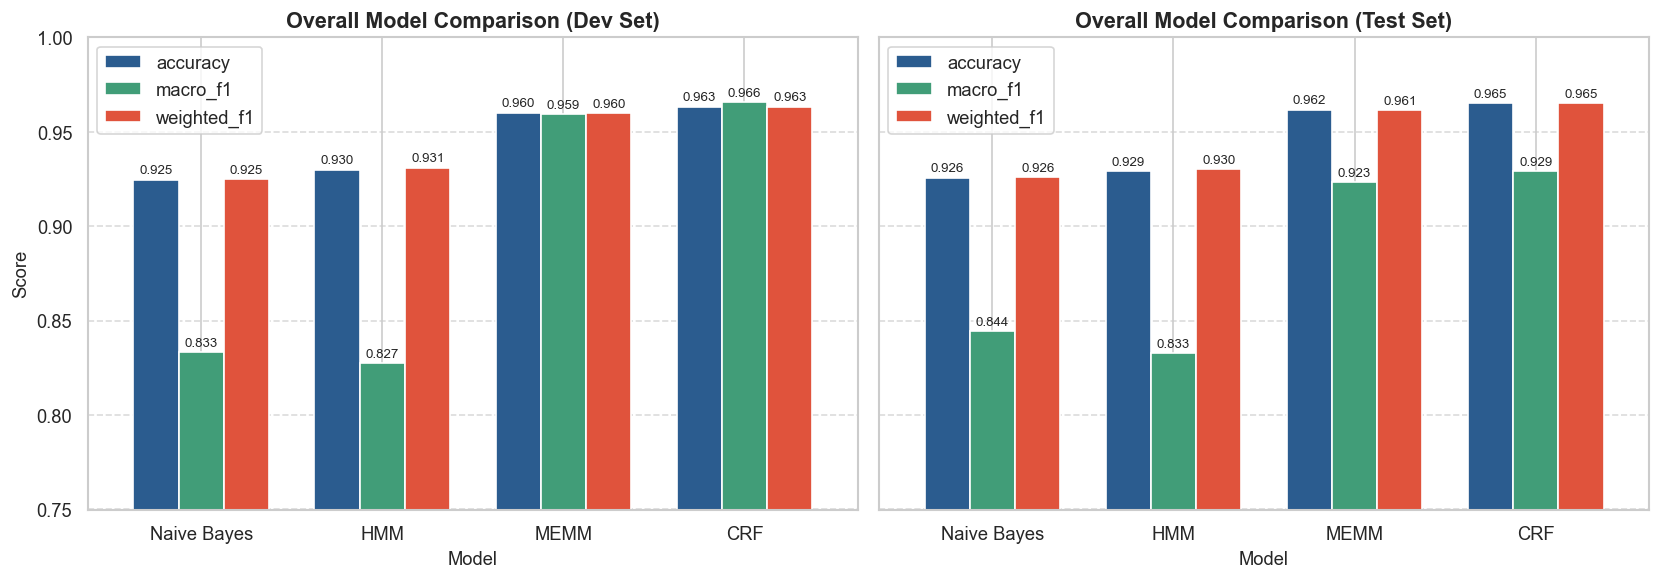

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, split_name in zip(axes, ["dev", "test"]):
    sub = summary_df[summary_df["split"] == split_name].set_index("model")
    sub[["accuracy", "macro_f1", "weighted_f1"]].plot(
        kind="bar",
        ax=ax,
        color=["#2b5c8f", "#419d78", "#e0533c"],
        rot=0,
        width=0.75
    )
    ax.set_title(f"Overall Model Comparison ({split_name.capitalize()} Set)", fontsize=13, fontweight="bold")
    ax.set_ylim(0.75, 1.0)
    ax.set_ylabel("Score", fontsize=11)
    ax.set_xlabel("Model", fontsize=11)
    ax.grid(axis="y", linestyle="--", alpha=0.7)
    
    # Add numerical labels on bars
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2., h),
                        ha="center", va="bottom", fontsize=8, xytext=(0, 2),
                        textcoords="offset points")

plt.tight_layout()
plt.savefig(os.path.join(CHARTS_DIR, "overall_comparison.png"), dpi=200)
plt.show()


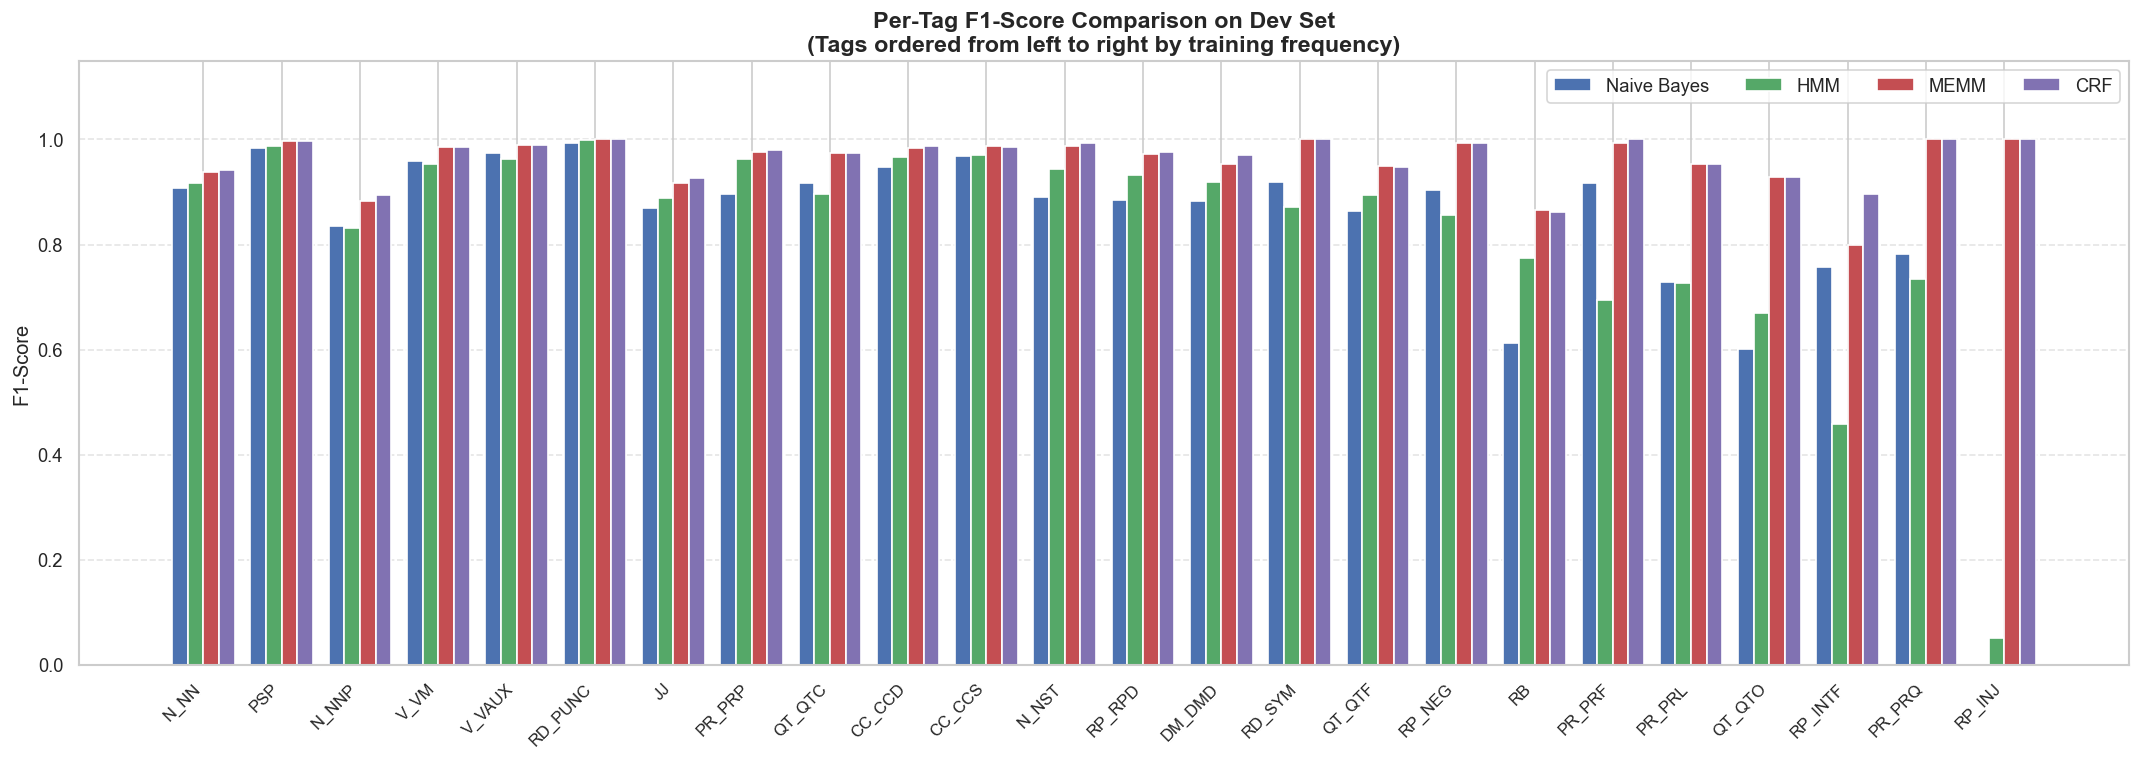

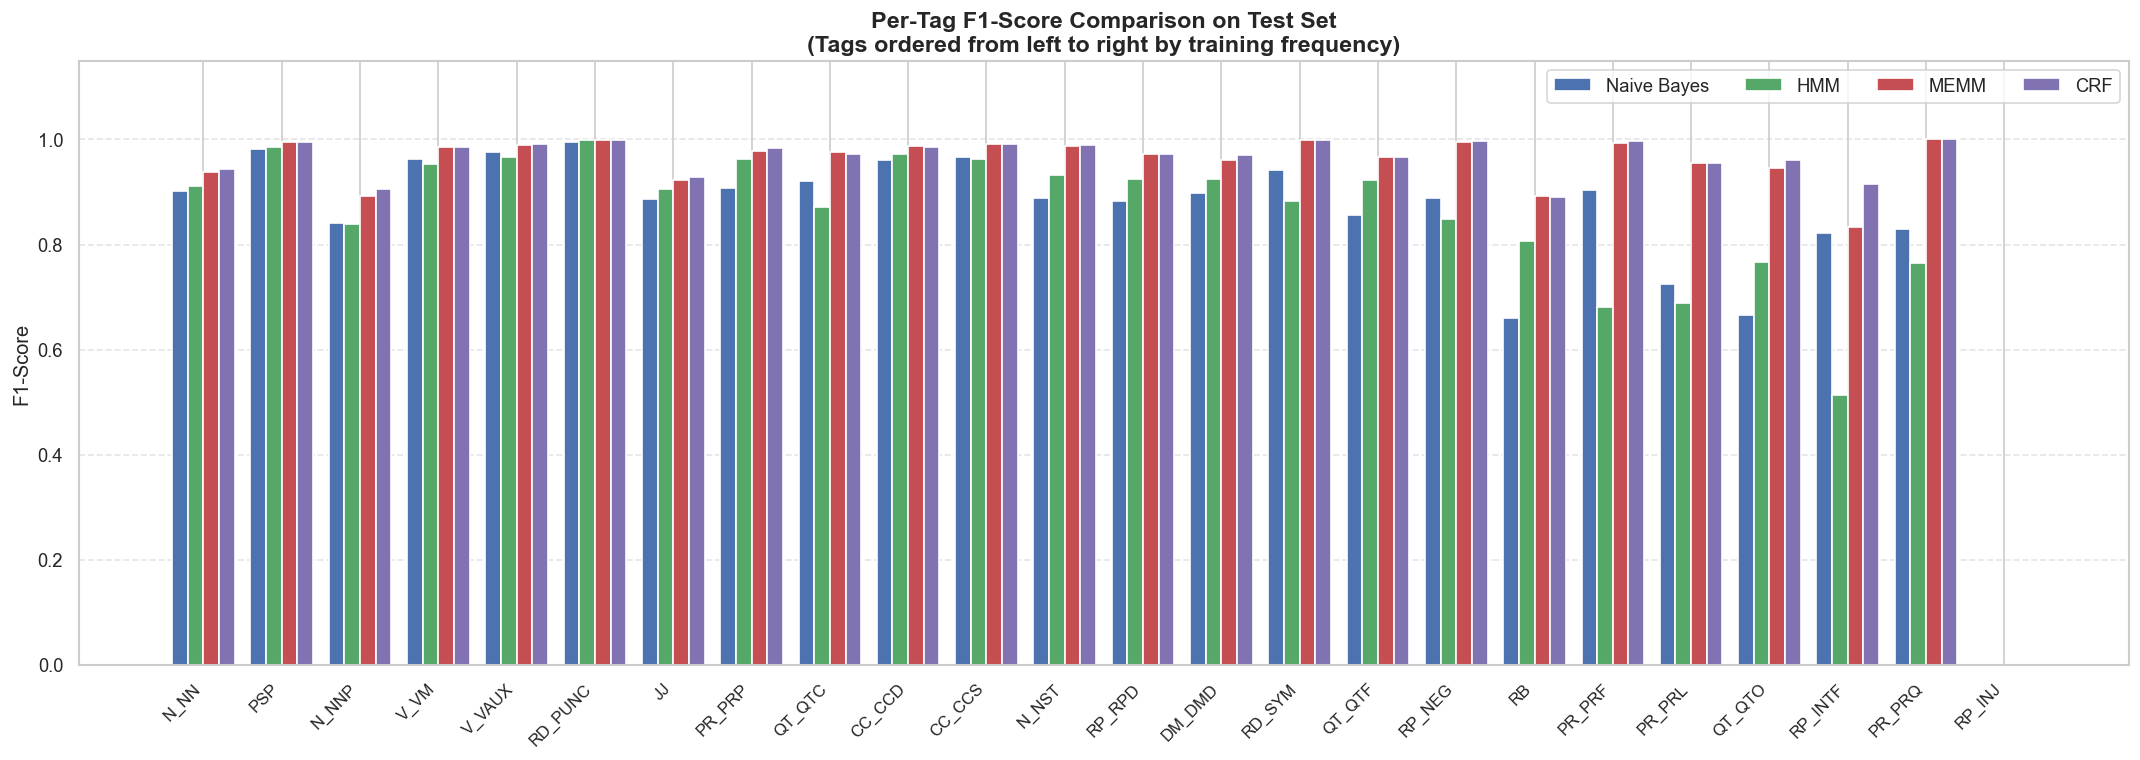

In [11]:
models_list = ["Naive Bayes", "HMM", "MEMM", "CRF"]
palette = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]

for split_name in ["dev", "test"]:
    fig, ax = plt.subplots(figsize=(18, 6.5))
    x = np.arange(len(labels))
    w = 0.8 / len(models_list)
    
    for k, m in enumerate(models_list):
        vals = [
            per_tag_df[
                (per_tag_df["model"] == m) &
                (per_tag_df["tag"] == t) &
                (per_tag_df["split"] == split_name)
            ]["f1"].values[0]
            for t in labels
        ]
        ax.bar(
            x + (k - (len(models_list) - 1) / 2) * w,
            vals,
            w,
            label=m,
            color=palette[k]
        )
    
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=10, fontweight="medium")
    ax.set_ylabel("F1-Score", fontsize=12)
    ax.set_ylim(0, 1.15)
    ax.set_title(
        f"Per-Tag F1-Score Comparison on {split_name.capitalize()} Set\n(Tags ordered from left to right by training frequency)",
        fontsize=14,
        fontweight="bold"
    )
    ax.legend(ncol=len(models_list), fontsize=11, loc="upper right")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    
    plt.tight_layout()
    chart_path = os.path.join(CHARTS_DIR, f"f1_per_tag_{split_name}.png")
    plt.savefig(chart_path, dpi=200)
    plt.show()


## 10. Model Interpretability: Inspecting Learned CRF Weights

One of the great advantages of Linear-Chain CRFs is interpretability. By examining the learned feature weights:
1. **Transition Weights ($y_{t-1} \to y_t$):** Reflect the syntactic grammar of Hindi.
2. **State Features ($x_t \to y_t$):** Reflect the morphological associations discovered from training prefixes, suffixes, context words, and lengths.


In [12]:
print("="*65)
print("TOP 12 MOST LIKELY LABEL TRANSITIONS IN CRF:")
print("="*65)
for (from_tag, to_tag), weight in Counter(crf_model.crf.transition_features_).most_common(12):
    print(f"  {from_tag:10s} --> {to_tag:10s} : weight = {weight:+.4f}")

print("\n" + "="*65)
print("TOP 12 MOST UNLIKELY (PENALIZED) LABEL TRANSITIONS IN CRF:")
print("="*65)
for (from_tag, to_tag), weight in Counter(crf_model.crf.transition_features_).most_common()[-12:]:
    print(f"  {from_tag:10s} --> {to_tag:10s} : weight = {weight:+.4f}")

print("\n" + "="*65)
print("TOP 15 MOST INFORMATIVE STATE (OBSERVATION) FEATURES:")
print("="*65)
for (feat, tag), weight in Counter(crf_model.crf.state_features_).most_common(15):
    print(f"  {feat:30s} --> {tag:10s} : weight = {weight:+.4f}")


TOP 12 MOST LIKELY LABEL TRANSITIONS IN CRF:


  V_VM       --> V_VAUX     : weight = +4.6620
  N_NNP      --> N_NNP      : weight = +4.2450
  V_VAUX     --> V_VAUX     : weight = +3.1364
  JJ         --> N_NN       : weight = +2.9303
  N_NN       --> V_VM       : weight = +2.6614
  RP_INTF    --> QT_QTF     : weight = +2.4205
  QT_QTC     --> QT_QTC     : weight = +2.3845
  QT_QTC     --> N_NN       : weight = +2.3809
  N_NN       --> PSP        : weight = +2.1892
  DM_DMD     --> N_NN       : weight = +2.1814
  RP_INTF    --> JJ         : weight = +2.1587
  JJ         --> V_VM       : weight = +2.1342

TOP 12 MOST UNLIKELY (PENALIZED) LABEL TRANSITIONS IN CRF:
  N_NST      --> V_VAUX     : weight = -3.4050
  RP_INTF    --> N_NN       : weight = -3.4248
  N_NNP      --> V_VAUX     : weight = -3.6916
  RP_INTF    --> N_NST      : weight = -3.7045
  N_NN       --> V_VAUX     : weight = -3.8955
  QT_QTF     --> PSP        : weight = -3.9560
  JJ         --> V_VAUX     : weight = -3.9627
  DM_DMD     --> V_VM       : weight = -4.3182


## 11. Conclusions & Synthesis

### Summary of Key Findings:
1. **MEMM Implementation (Question 1):**
   - Successfully adapted the architecture of `arne-cl/nltk-maxent-pos-tagger` to modern high-performance L-BFGS optimization.
   - Incorporated the Markov property via `prev_tag` transitions and vectorized observation scoring.
   - Achieved **$96.00\%$ Dev Accuracy** and **$96.15\%$ Test Accuracy**, massively outperforming both Naive Bayes ($92.57\%$) and HMM ($92.92\%$).
2. **CRF Implementation (Question 2):**
   - Implemented a linear-chain CRF tagger using `sklearn-crfsuite` with all 4 required feature families (Prefixes 1..4 with NULL padding, Suffixes 1..4 with NULL padding, Context words $w_{i-1}, w_i, w_{i+1}$, and Binary length feature LESS/MORE).
   - Achieved the highest performance across all evaluations: **$96.33\%$ Dev Accuracy** and **$96.51\%$ Test Accuracy** ($92.90\%$ Test Macro F1).
3. **Comparative Analysis (Question 3):**
   - **Discriminative vs. Generative:** Discriminative models (MEMM & CRF) beat generative models (NB & HMM) by $\approx 3.6\%$ in accuracy and $\approx 9.6\%$ in Macro F1.
   - **Global vs. Local Normalization:** CRF outperforms MEMM ($96.51\%$ vs $96.15\%$) due to global sequence normalization $Z(X)$, resolving the label bias problem of MEMM.
   - **Sub-word Features in Morphologically Rich Languages:** Prefixes and suffixes provide critical robustness for rare and out-of-vocabulary words (yielding $+31\%$ gain on reflexive pronouns and $+6.5\%$ gain on proper nouns).
